In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("messy_orders.csv")
df

,order_id,customer_name,age,gender,city,product_category,product,quantity,unit_price,discount,order_date,payment_method,rating,delivery_days
0,1001,Ravi Kumar,28.0,M,Hyderabad,Electronics,Wireless Mouse,2,$25.50,0.10,2026-01-05,Credit Card,4.0,3.0
1,1002,priya sharma,34.0,F,mumbai,electronics,Bluetooth Speaker,1,"$1,200.00",0.05,05/01/2026,UPI,5.0,2.0
2,1003,ANIL VERMA,NaN,M,Delhi,Clothing,Jacket,1,89.99,0.00,2026-01-07,Cash,3.0,5.0
3,1004,Sneha Reddy,29.0,f,Hyderabad,Home & Kitchen,Mixer Grinder,1,120,0.15,Jan 9 2026,Debit Card,4.0,4.0
4,1005,Karthik Rao,41.0,Male,Bangalore,Books,Python Cookbook,3,15.00,0.00,2026-01-10,UPI,5.0,2.0
5,1006,Meena Iyer,-25.0,Female,Chennai,Clothing,T-Shirt,4,12.5,0.20,2026-01-11,Credit Card,2.0,6.0
6,1007,Rahul Singh,52.0,M,Delhi,Electronics,Laptop,1,"$45,000.00",0.08,2026-01-12,Credit Card,5.0,3.0
7,1008,Ravi Kumar,28.0,M,Hyderabad,Electronics,Wireless Mouse,2,$25.50,0.10,2026-01-05,Credit Card,4.0,3.0
8,1009,Divya Nair,31.0,F,Kochi,Books,Data Science Handbook,2,22.00,NaN,2026-01-14,Net Banking,NaN,4.0
9,1010,Arjun Mehta,23.0,M,Pune,Electronics,Headphones,1,NaN,0.10,2026-01-15,UPI,4.0,2.0


In [5]:
df.describe()

,order_id,age,quantity,discount,rating,delivery_days
count,40.000000,37.000000,40.000000,39.000000,37.000000,39.000000
mean,1020.500000,59.891892,1.600000,0.092051,3.918919,3.820513
std,11.690452,159.256045,1.007663,0.078579,1.037582,2.101025
min,1001.000000,-25.000000,-1.000000,0.000000,1.000000,1.000000
25%,1010.750000,28.000000,1.000000,0.025000,3.000000,2.000000
50%,1020.500000,34.000000,1.000000,0.100000,4.000000,3.000000
75%,1030.250000,43.000000,2.000000,0.120000,5.000000,5.000000
max,1040.000000,999.000000,5.000000,0.300000,5.000000,10.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          40 non-null     int64  
 1   customer_name     40 non-null     object 
 2   age               37 non-null     float64
 3   gender            40 non-null     object 
 4   city              40 non-null     object 
 5   product_category  40 non-null     object 
 6   product           40 non-null     object 
 7   quantity          40 non-null     int64  
 8   unit_price        39 non-null     object 
 9   discount          39 non-null     float64
 10  order_date        40 non-null     object 
 11  payment_method    40 non-null     object 
 12  rating            37 non-null     float64
 13  delivery_days     39 non-null     float64
dtypes: float64(4), int64(2), object(8)
memory usage: 4.5+ KB


In [7]:
df["customer_name"] = df["customer_name"].str.lower().copy()

In [8]:
df = df.dropna(subset="age").copy()

In [9]:
df["age"] = df["age"].astype("int").copy()

In [10]:
df = df[ (df["age"]>0) &( df["age"]<100)].copy()

In [11]:
df["gender"] = df["gender"].str.lower().copy()

In [12]:
df["gender"] = df["gender"].replace({"m":"male","f":"female"}).copy()

In [13]:
df["city"] = df["city"].str.lower().copy()

In [14]:
df["product_category"] = df["product_category"].str.lower().copy()

In [15]:
df["product"] = df["product"].str.lower().copy()

In [16]:
df = df[df["quantity"]>0].copy()

In [17]:
df = df.dropna(subset="unit_price").copy()

In [18]:
df["unit_price"] = df["unit_price"].str.strip("$").copy()

In [19]:
df["discount"] = df["discount"].fillna(0.00)

In [20]:
df["order_date"] = pd.to_datetime(df["order_date"] , format="mixed" , errors="coerce").copy()

In [21]:
df["payment_method"] = df["payment_method"].str.lower().copy()

In [22]:
df["rating"] = df["rating"].fillna(0.0).copy()

In [23]:
df["delivery_days"] = df["delivery_days"].astype("int")

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33 entries, 0 to 39
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          33 non-null     int64         
 1   customer_name     33 non-null     object        
 2   age               33 non-null     int64         
 3   gender            33 non-null     object        
 4   city              33 non-null     object        
 5   product_category  33 non-null     object        
 6   product           33 non-null     object        
 7   quantity          33 non-null     int64         
 8   unit_price        33 non-null     object        
 9   discount          33 non-null     float64       
 10  order_date        33 non-null     datetime64[ns]
 11  payment_method    33 non-null     object        
 12  rating            33 non-null     float64       
 13  delivery_days     33 non-null     int64         
dtypes: datetime64[ns](1), float64(2),

In [25]:
df["unit_price"] = df["unit_price"].astype("str").str.replace(",","").astype("float")

In [26]:
df["total_amount_paid"] = df['quantity'] * df['unit_price'] * (1 - df['discount'])

In [46]:
df["customer_name"] = df["customer_name"].str.strip().str.lower()

In [49]:
df.duplicated(subset=["customer_name"])

0     False
1     False
3     False
4     False
6     False
7      True
8     False
10    False
11    False
12    False
14    False
15    False
16    False
18    False
19    False
20     True
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
33    False
34    False
36    False
37    False
38    False
39    False
dtype: bool

In [51]:
df = df.drop_duplicates(subset=["customer_name"]).copy()

In [52]:
df

,order_id,customer_name,age,gender,city,product_category,product,quantity,unit_price,discount,order_date,payment_method,rating,delivery_days,total_amount_paid
0,1001,ravi kumar,28,male,hyderabad,electronics,wireless mouse,2,25.50,0.10,2026-01-05,credit card,4.0,3,45.9000
1,1002,priya sharma,34,female,mumbai,electronics,bluetooth speaker,1,1200.00,0.05,2026-05-01,upi,5.0,2,1140.0000
3,1004,sneha reddy,29,female,hyderabad,home & kitchen,mixer grinder,1,120.00,0.15,2026-01-09,debit card,4.0,4,102.0000
4,1005,karthik rao,41,male,bangalore,books,python cookbook,3,15.00,0.00,2026-01-10,upi,5.0,2,45.0000
6,1007,rahul singh,52,male,delhi,electronics,laptop,1,45000.00,0.08,2026-01-12,credit card,5.0,3,41400.0000
8,1009,divya nair,31,female,kochi,books,data science handbook,2,22.00,0.00,2026-01-14,net banking,0.0,4,44.0000
10,1011,pooja gupta,37,female,hyderabad,home & kitchen,air fryer,1,150.00,0.12,2026-01-15,credit card,5.0,3,132.0000
11,1012,suresh babu,48,male,chennai,clothing,jeans,2,45.00,0.00,2026-01-17,cash,3.0,7,90.0000
12,1013,anjali das,26,female,kolkata,books,novel set,5,8.75,0.05,2026-01-18,upi,4.0,5,41.5625
14,1015,neha kapoor,30,female,delhi,clothing,dress,1,75.00,0.25,2026-01-20,debit card,0.0,4,56.2500


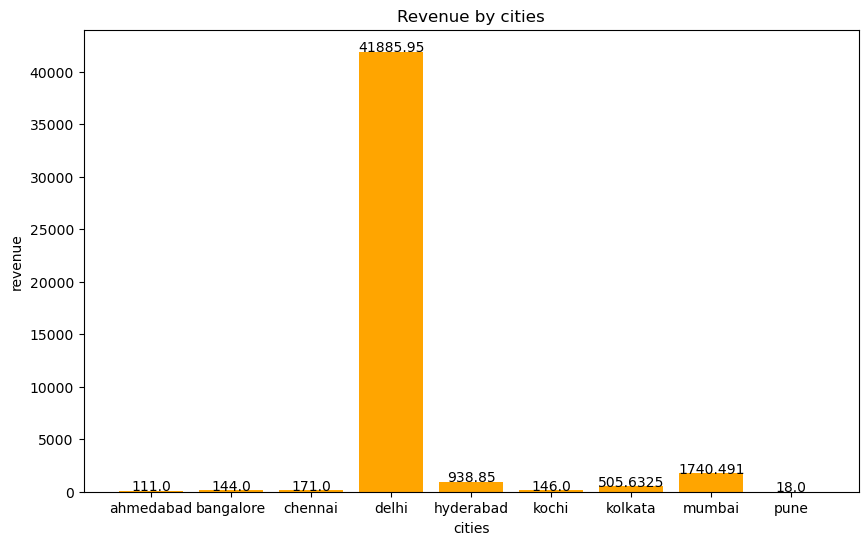

In [64]:
revenue_by_city = df.groupby("city")["total_amount_paid"].sum()

plt.figure(figsize=(10,6))
plt.bar(revenue_by_city.index , revenue_by_city.values ,color="orange")

for i in range(len(revenue_by_city.index)):
    plt.text(i , revenue_by_city.values[i]+0.8 , str(revenue_by_city.values[i]) , ha="center")

plt.title("Revenue by cities")
plt.xlabel("cities")
plt.ylabel("revenue")

plt.show()

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31 entries, 0 to 39
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   order_id           31 non-null     int64         
 1   customer_name      31 non-null     object        
 2   age                31 non-null     int64         
 3   gender             31 non-null     object        
 4   city               31 non-null     object        
 5   product_category   31 non-null     object        
 6   product            31 non-null     object        
 7   quantity           31 non-null     int64         
 8   unit_price         31 non-null     float64       
 9   discount           31 non-null     float64       
 10  order_date         31 non-null     datetime64[ns]
 11  payment_method     31 non-null     object        
 12  rating             31 non-null     float64       
 13  delivery_days      31 non-null     int64         
 14  total_amount_paid

In [66]:
revenue_by_product_cat = df.groupby("product_category")["total_amount_paid"].sum()

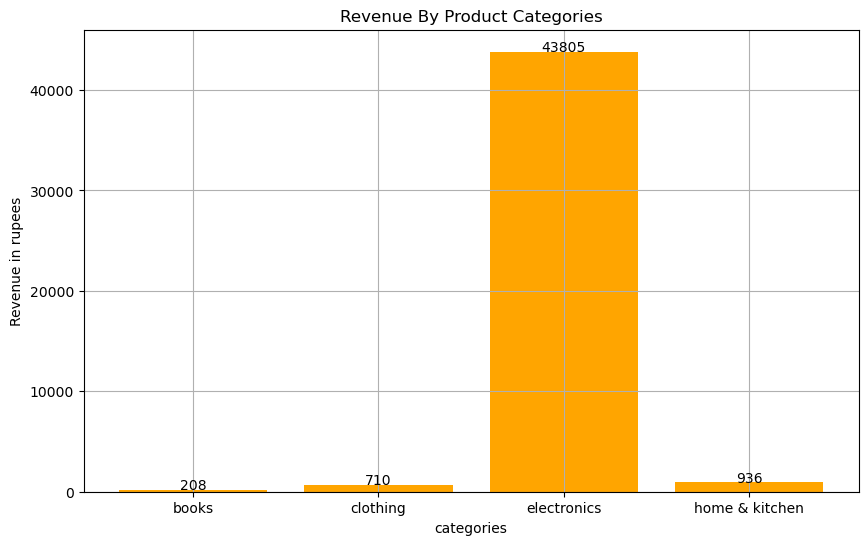

In [73]:
plt.figure(figsize=(10,6))
plt.bar(revenue_by_product_cat.index , revenue_by_product_cat.values , color="orange")
plt.title("Revenue By Product Categories")
plt.xlabel("categories")
plt.ylabel("Revenue in rupees")
plt.grid()

for i in range(len(revenue_by_product_cat.index)):
    plt.text(i , revenue_by_product_cat.values[i] , str(int(revenue_by_product_cat.values[i])) , ha="center" )

plt.show()

In [77]:
payment_methods_and_amountspend = df.groupby("payment_method")["total_amount_paid"].sum()

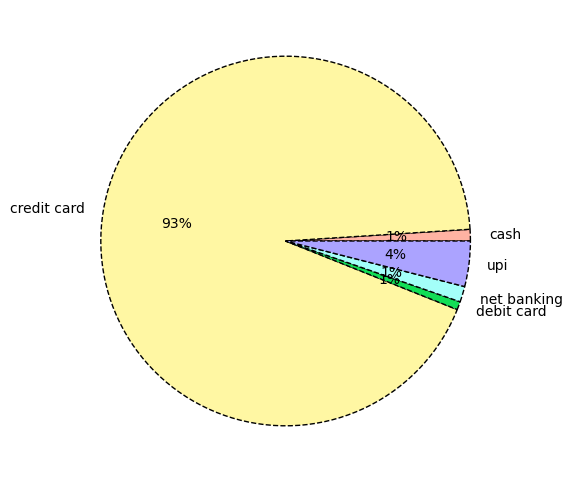

In [87]:
pay_methods = [i for i in payment_methods_and_amountspend.index]
colors = ["#FFB3A3","#FFF7A3","#12DE56","#A3FFF9","#ABA3FF"]

plt.figure(figsize=(10,6))
plt.pie(payment_methods_and_amountspend.values , labels=pay_methods , 
        colors=colors ,
        wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'linestyle': '--'},
        autopct="%1.f%%")
plt.show()

In [88]:
df

,order_id,customer_name,age,gender,city,product_category,product,quantity,unit_price,discount,order_date,payment_method,rating,delivery_days,total_amount_paid
0,1001,ravi kumar,28,male,hyderabad,electronics,wireless mouse,2,25.50,0.10,2026-01-05,credit card,4.0,3,45.9000
1,1002,priya sharma,34,female,mumbai,electronics,bluetooth speaker,1,1200.00,0.05,2026-05-01,upi,5.0,2,1140.0000
3,1004,sneha reddy,29,female,hyderabad,home & kitchen,mixer grinder,1,120.00,0.15,2026-01-09,debit card,4.0,4,102.0000
4,1005,karthik rao,41,male,bangalore,books,python cookbook,3,15.00,0.00,2026-01-10,upi,5.0,2,45.0000
6,1007,rahul singh,52,male,delhi,electronics,laptop,1,45000.00,0.08,2026-01-12,credit card,5.0,3,41400.0000
8,1009,divya nair,31,female,kochi,books,data science handbook,2,22.00,0.00,2026-01-14,net banking,0.0,4,44.0000
10,1011,pooja gupta,37,female,hyderabad,home & kitchen,air fryer,1,150.00,0.12,2026-01-15,credit card,5.0,3,132.0000
11,1012,suresh babu,48,male,chennai,clothing,jeans,2,45.00,0.00,2026-01-17,cash,3.0,7,90.0000
12,1013,anjali das,26,female,kolkata,books,novel set,5,8.75,0.05,2026-01-18,upi,4.0,5,41.5625
14,1015,neha kapoor,30,female,delhi,clothing,dress,1,75.00,0.25,2026-01-20,debit card,0.0,4,56.2500


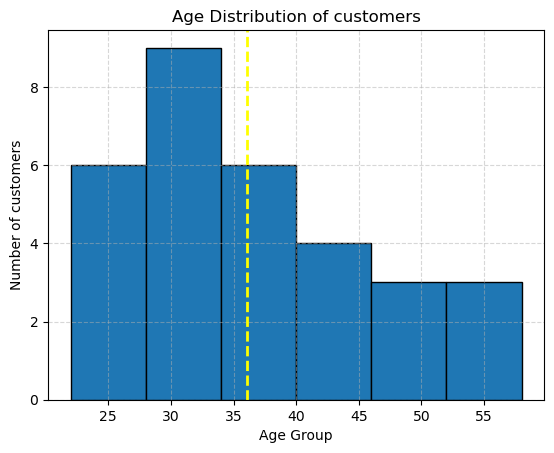

In [98]:
plt.hist(df["age"] , bins=6 , edgecolor="black")
plt.title('Age Distribution of customers')
plt.xlabel('Age Group')
plt.ylabel('Number of customers')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axvline(np.mean(df["age"]), color='yellow', linestyle='--', linewidth=2, label='Average Age')
plt.show()

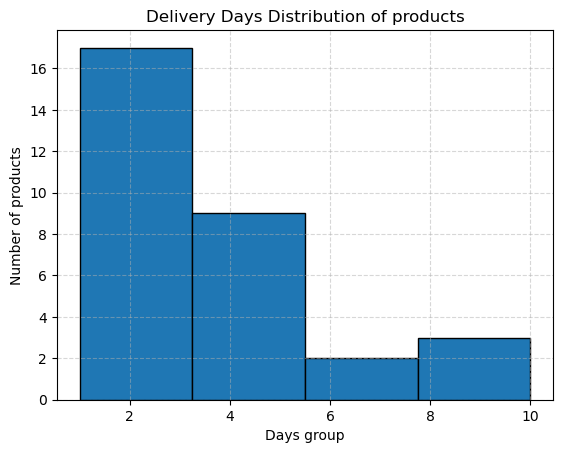

In [109]:
plt.hist(df["delivery_days"] , bins=4 , edgecolor="black")
plt.title("Delivery Days Distribution of products")
plt.xlabel('Days group')
plt.ylabel('Number of products')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [100]:
df

,order_id,customer_name,age,gender,city,product_category,product,quantity,unit_price,discount,order_date,payment_method,rating,delivery_days,total_amount_paid
0,1001,ravi kumar,28,male,hyderabad,electronics,wireless mouse,2,25.50,0.10,2026-01-05,credit card,4.0,3,45.9000
1,1002,priya sharma,34,female,mumbai,electronics,bluetooth speaker,1,1200.00,0.05,2026-05-01,upi,5.0,2,1140.0000
3,1004,sneha reddy,29,female,hyderabad,home & kitchen,mixer grinder,1,120.00,0.15,2026-01-09,debit card,4.0,4,102.0000
4,1005,karthik rao,41,male,bangalore,books,python cookbook,3,15.00,0.00,2026-01-10,upi,5.0,2,45.0000
6,1007,rahul singh,52,male,delhi,electronics,laptop,1,45000.00,0.08,2026-01-12,credit card,5.0,3,41400.0000
8,1009,divya nair,31,female,kochi,books,data science handbook,2,22.00,0.00,2026-01-14,net banking,0.0,4,44.0000
10,1011,pooja gupta,37,female,hyderabad,home & kitchen,air fryer,1,150.00,0.12,2026-01-15,credit card,5.0,3,132.0000
11,1012,suresh babu,48,male,chennai,clothing,jeans,2,45.00,0.00,2026-01-17,cash,3.0,7,90.0000
12,1013,anjali das,26,female,kolkata,books,novel set,5,8.75,0.05,2026-01-18,upi,4.0,5,41.5625
14,1015,neha kapoor,30,female,delhi,clothing,dress,1,75.00,0.25,2026-01-20,debit card,0.0,4,56.2500


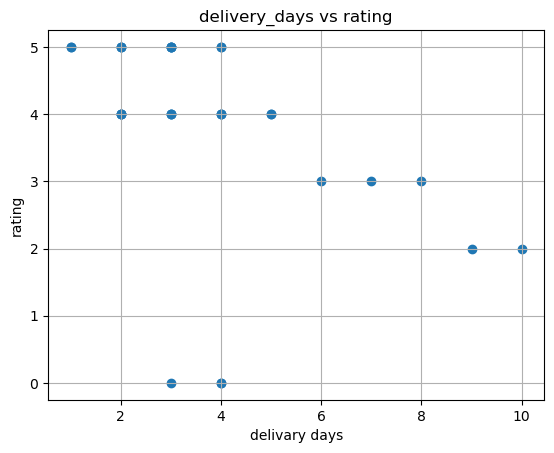

In [111]:
plt.scatter(df["delivery_days"], df["rating"])
plt.title('delivery_days vs rating')
plt.xlabel('delivary days')
plt.ylabel('rating')
plt.grid(True)
plt.show()